In [1]:
!nvidia-smi

Mon Oct 26 22:11:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA H100 80GB HBM3          On  |   00000000:1B:00.0 Off |                    0 |
| N/A   49C    P0            509W /  700W |   51868MiB /  81559MiB |    100%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [4]:
base_salario = pd.read_parquet(
    "caged_salary_analysis.parquet"
)

print(base_salario.shape)

(1936104, 35)


In [5]:
def harmonizar_sexo(row):
    sexo = row["sexo"]
    ano = row["ano_analise"]

    if pd.isna(sexo):
        return pd.NA

    sexo = str(sexo).strip().replace(".0", "")

    if ano <= 2019:
        return {"1": "Masculino", "2": "Feminino"}.get(sexo, pd.NA)
    else:
        return {"1": "Masculino", "3": "Feminino"}.get(sexo, pd.NA)

base_salario["sexo_harmonizado"] = base_salario.apply(
    harmonizar_sexo,
    axis=1
)

base_salario["sexo_harmonizado"].value_counts(dropna=False)

sexo_harmonizado
Masculino    1295838
Feminino      640263
NaN                3
Name: count, dtype: int64

In [6]:
def harmonizar_sexo(row):
    sexo = row["sexo"]
    ano = row["ano_analise"]

    if pd.isna(sexo):
        return pd.NA

    sexo = str(sexo).strip().replace(".0", "")

    if ano <= 2019:
        return {"1": "Masculino", "2": "Feminino"}.get(sexo, pd.NA)
    else:
        return {"1": "Masculino", "3": "Feminino"}.get(sexo, pd.NA)

base_salario["sexo_harmonizado"] = base_salario.apply(
    harmonizar_sexo,
    axis=1
)

base_salario["sexo_harmonizado"].value_counts(dropna=False)

sexo_harmonizado
Masculino    1295838
Feminino      640263
NaN                3
Name: count, dtype: int64

In [7]:
base_modelo = (
    base_salario[
        [
            "salario_consolidado",
            "sexo_harmonizado",
            "escolaridade_clean",
            "faixa_etaria_harmonizada",
            "cbo_grupo",
            "ano_analise"
        ]
    ]
    .dropna()
    .copy()
)

print(len(base_modelo))

1914957


In [8]:
# ============================================================
# SELEÇÃO DA FAMÍLIA PROBABILÍSTICA
# ============================================================

import warnings
import numpy as np
import pandas as pd
import scipy.stats as stats

import gamlss as gl
from gamlss import gamlss, GAIC

# ------------------------------------------------------------
# 1. Configuração reprodutível
# ------------------------------------------------------------

Y = "salario_consolidado"

N_AMOSTRA = 100_000
SEED = 42
N_CYC = 100

# Usar a mesma população analítica do modelo final
amostra_familias = (
    base_modelo[[Y]]
    .dropna()
    .sample(
        n=min(N_AMOSTRA, len(base_modelo)),
        random_state=SEED
    )
    .copy()
)

print("N da amostra:", len(amostra_familias))
print(amostra_familias[Y].describe())

N da amostra: 100000
count    100000.000000
mean       2185.793360
std        4278.346834
min         170.000000
25%        1280.000000
50%        1601.845000
75%        1920.600000
max      215000.000000
Name: salario_consolidado, dtype: float64


In [9]:
# ------------------------------------------------------------
# 2. Famílias candidatas
# ------------------------------------------------------------

familias = {
    "Lognormal": gl.LOGNO(),
    "Gamma": gl.GA(),
    "Gamma generalizada": gl.GG(),
    "Weibull": gl.WEI(),
    "BCCG": gl.BCCG(),
    "BCT": gl.BCT(),
    "BCPE": gl.BCPE(),
}

In [10]:
# ------------------------------------------------------------
# 3. Ajuste e comparação
# ------------------------------------------------------------

resultados = []
modelos_familias = {}

formula_familia = f"{Y} ~ 1"

for nome, familia in familias.items():

    print("\n" + "=" * 70)
    print(f"FAMÍLIA: {nome}")
    print("=" * 70)

    registro = {
        "familia": nome,
        "convergiu": False,
        "deviance": np.nan,
        "GAIC": np.nan,
        "SBC": np.nan,
        "df": np.nan,
        "resid_media": np.nan,
        "resid_dp": np.nan,
        "resid_assimetria": np.nan,
        "resid_curtose": np.nan,
        "qq_r": np.nan,
        "pct_abs_gt2": np.nan,
        "pct_abs_gt3": np.nan,
        "observacao": ""
    }

    try:

        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always")

            modelo = gamlss(
                formula_familia,
                family=familia,
                data=amostra_familias,
                n_cyc=N_CYC
            )

        # Capturar avisos do algoritmo
        mensagens = [str(w.message) for w in avisos]

        nao_convergiu = any(
            "not yet converged" in m.lower()
            for m in mensagens
        )

        registro["convergiu"] = not nao_convergiu

        registro["deviance"] = modelo.G_deviance
        registro["GAIC"] = GAIC(modelo, k=2)
        registro["SBC"] = modelo.sbc
        registro["df"] = modelo.df_fit

        # ----------------------------------------------------
        # Diagnósticos com resíduos quantílicos normalizados
        # ----------------------------------------------------

        residuos = np.asarray(
            modelo.get_residuals(),
            dtype=float
        )

        residuos = residuos[np.isfinite(residuos)]

        registro["resid_media"] = np.mean(residuos)
        registro["resid_dp"] = np.std(residuos, ddof=1)

        registro["resid_assimetria"] = stats.skew(
            residuos,
            bias=False
        )

        registro["resid_curtose"] = stats.kurtosis(
            residuos,
            fisher=True,
            bias=False
        )

        # Correlação do QQ-plot
        (_, _), (_, _, qq_r) = stats.probplot(
            residuos,
            dist="norm"
        )

        registro["qq_r"] = qq_r

        registro["pct_abs_gt2"] = (
            np.mean(np.abs(residuos) > 2) * 100
        )

        registro["pct_abs_gt3"] = (
            np.mean(np.abs(residuos) > 3) * 100
        )

        if mensagens:
            registro["observacao"] = " | ".join(mensagens)
        else:
            registro["observacao"] = "Sem avisos"

        modelos_familias[nome] = modelo

    except Exception as e:

        registro["convergiu"] = False
        registro["observacao"] = (
            f"{type(e).__name__}: {str(e)}"
        )

        print(
            f"\nERRO EM {nome}: "
            f"{type(e).__name__}: {e}"
        )

    resultados.append(registro)


FAMÍLIA: Lognormal
GAMLSS-RS iteration 1: Global Deviance = 1644468.1284
GAMLSS-RS iteration 2: Global Deviance = 1644468.1284

FAMÍLIA: Gamma
GAMLSS-RS iteration 1: Global Deviance = 1715040.3519
GAMLSS-RS iteration 2: Global Deviance = 1715040.3519

FAMÍLIA: Gamma generalizada
GAMLSS-RS iteration 1: Global Deviance = 1670754.0550
GAMLSS-RS iteration 2: Global Deviance = 1624659.4516
GAMLSS-RS iteration 3: Global Deviance = 1616977.2550
GAMLSS-RS iteration 4: Global Deviance = 1615883.4411
GAMLSS-RS iteration 5: Global Deviance = 1615726.0762
GAMLSS-RS iteration 6: Global Deviance = 1615702.8843
GAMLSS-RS iteration 7: Global Deviance = 1615699.5778
GAMLSS-RS iteration 8: Global Deviance = 1615699.0740
GAMLSS-RS iteration 9: Global Deviance = 1615698.9841
GAMLSS-RS iteration 10: Global Deviance = 1615698.9763
GAMLSS-RS iteration 11: Global Deviance = 1615698.9717
GAMLSS-RS iteration 12: Global Deviance = 1615698.9716

FAMÍLIA: Weibull
GAMLSS-RS iteration 1: Global Deviance = 1827115.8

In [11]:
# ------------------------------------------------------------
# 4. Tabela comparativa
# ------------------------------------------------------------

tabela_familias = pd.DataFrame(resultados)

# Delta GAIC somente entre modelos convergidos
mask_conv = tabela_familias["convergiu"]

if mask_conv.any():

    melhor_gaic = tabela_familias.loc[
        mask_conv,
        "GAIC"
    ].min()

    tabela_familias["delta_GAIC"] = (
        tabela_familias["GAIC"] - melhor_gaic
    )

else:
    tabela_familias["delta_GAIC"] = np.nan


tabela_familias = tabela_familias[
    [
        "familia",
        "convergiu",
        "deviance",
        "GAIC",
        "delta_GAIC",
        "SBC",
        "df",
        "resid_media",
        "resid_dp",
        "resid_assimetria",
        "resid_curtose",
        "qq_r",
        "pct_abs_gt2",
        "pct_abs_gt3",
        "observacao"
    ]
]

tabela_familias = tabela_familias.sort_values(
    ["convergiu", "GAIC"],
    ascending=[False, True]
)

pd.set_option("display.max_columns", None)

display(tabela_familias)

,familia,convergiu,deviance,GAIC,delta_GAIC,SBC,df,resid_media,resid_dp,resid_assimetria,resid_curtose,qq_r,pct_abs_gt2,pct_abs_gt3,observacao
5,BCT,True,1.589128e+06,1.589136e+06,0.000000,1.589174e+06,4.0,-0.021981,1.001295,0.080542,-0.102892,0.995981,5.142000,0.015000,Sem avisos
2,Gamma generalizada,True,1.615699e+06,1.615705e+06,26569.427677,1.615734e+06,3.0,-0.006165,1.002705,0.120816,5.450360,0.956325,6.172000,2.213000,Sem avisos
0,Lognormal,True,1.644468e+06,1.644472e+06,55336.584427,1.644491e+06,2.0,-0.000610,0.997379,2.377725,10.668757,0.893390,4.731331,2.599182,Sem avisos
1,Gamma,True,1.715040e+06,1.715044e+06,125908.807916,1.715063e+06,2.0,-0.063105,0.876370,4.085073,23.569089,0.793852,3.179532,2.021517,Sem avisos
3,Weibull,True,1.735674e+06,1.735678e+06,146541.999211,1.735697e+06,2.0,0.072248,0.713468,4.665943,30.831959,0.765319,2.653308,1.481289,Sem avisos
6,BCPE,False,2.461321e+06,2.461329e+06,872193.232639,2.461367e+06,4.0,-2.429523,0.408662,5.065211,28.364293,0.673312,95.746000,0.131000,Algorithm RS has not yet converged
4,BCCG,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ValueError: mu must be positive


In [13]:
tabela_familias.to_csv(
    "comparacao_familias_gamlss.csv",
    index=False,
    encoding="utf-8-sig"
)

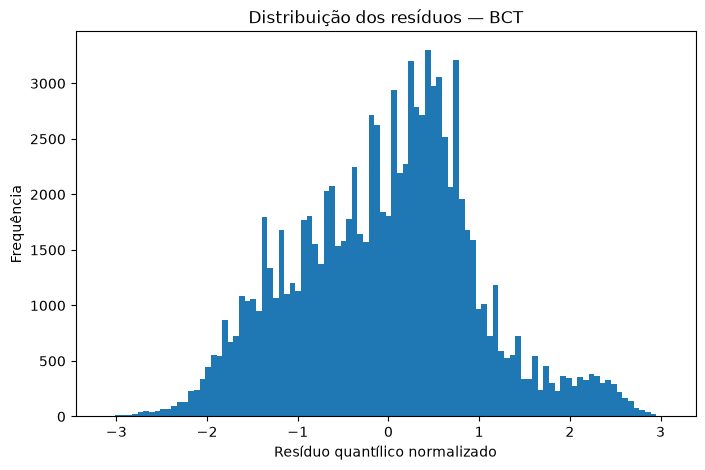

In [14]:
import matplotlib.pyplot as plt

modelo_bct = modelos_familias["BCT"]

res_bct = pd.Series(
    modelo_bct.get_residuals()
).dropna()

plt.figure(figsize=(8, 5))
plt.hist(res_bct, bins=100)
plt.xlabel("Resíduo quantílico normalizado")
plt.ylabel("Frequência")
plt.title("Distribuição dos resíduos — BCT")
plt.show()